<a href="https://colab.research.google.com/github/carrotst1ck/ML-SU-3-Course/blob/main/pr8_ml.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!python3 -c "import sklearn, matplotlib; print(sklearn.__version__, matplotlib.__version__)"

1.6.1 3.10.0


In [2]:
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

X2, y2 = make_moons(n_samples=300, noise=0.25, random_state=42)
X2 = StandardScaler().fit_transform(X2)
print("объектов:", len(X2), " классы:", np.bincount(y2))

объектов: 300  классы: [150 150]


In [3]:
def plot_boundary(model, X, y, title, fname):
    xx, yy = np.meshgrid(np.linspace(-3, 3, 300), np.linspace(-3, 3, 300))
    zz = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    plt.figure(figsize=(5, 4))
    plt.contourf(xx, yy, zz, alpha=0.25, cmap="coolwarm")
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", s=18, edgecolor="k")
    sv = model.support_vectors_
    plt.scatter(sv[:, 0], sv[:, 1], s=70, facecolors="none", edgecolors="k")
    plt.title(f"{title}: train acc={model.score(X, y):.3f}, SV={len(sv)}")
    plt.tight_layout(); plt.savefig(fname, dpi=120); plt.close()

In [4]:
lin = SVC(kernel="linear", C=1).fit(X2, y2)
plot_boundary(lin, X2, y2, "linear, C=1", "svm_linear.png")
print("linear: acc=%.3f  опорных=%d" % (lin.score(X2, y2), len(lin.support_vectors_)))

linear: acc=0.860  опорных=101


In [5]:
rbf = SVC(kernel="rbf", C=1, gamma="scale").fit(X2, y2)
plot_boundary(rbf, X2, y2, "rbf, C=1", "svm_rbf.png")
print("rbf:    acc=%.3f  опорных=%d" % (rbf.score(X2, y2), len(rbf.support_vectors_)))

rbf:    acc=0.910  опорных=92


In [6]:
for C in [0.01, 1, 100]:
    m = SVC(kernel="rbf", C=C, gamma="scale").fit(X2, y2)
    plot_boundary(m, X2, y2, f"rbf, C={C}", f"svm_rbf_C{C}.png")
    print(f"C={C:<5} acc={m.score(X2, y2):.3f}  опорных={len(m.support_vectors_)}")

C=0.01  acc=0.870  опорных=300
C=1     acc=0.910  опорных=92
C=100   acc=0.937  опорных=57


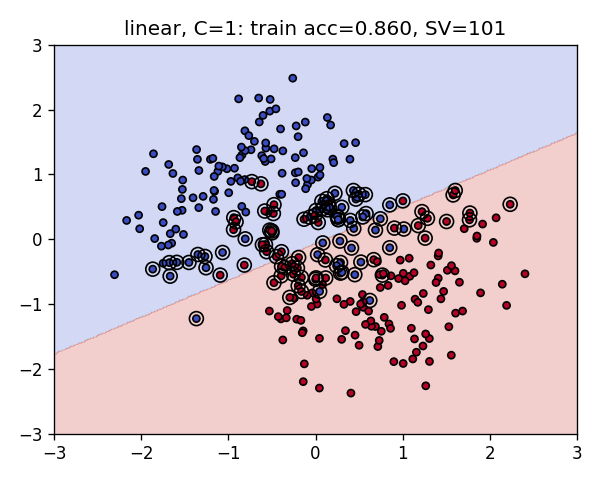

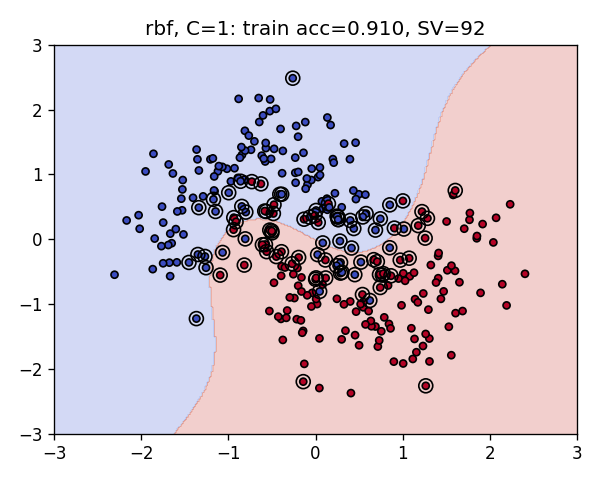

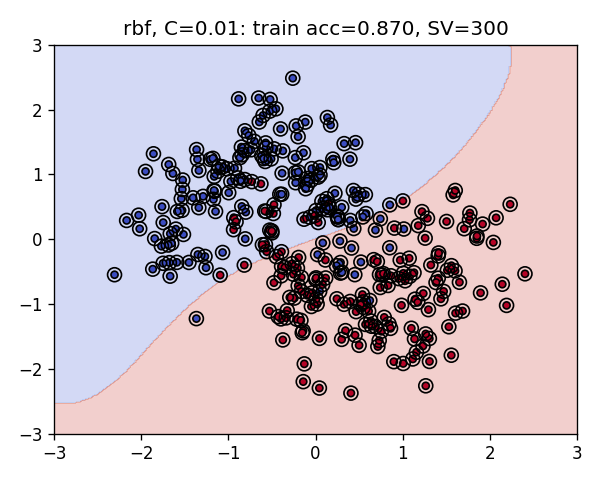

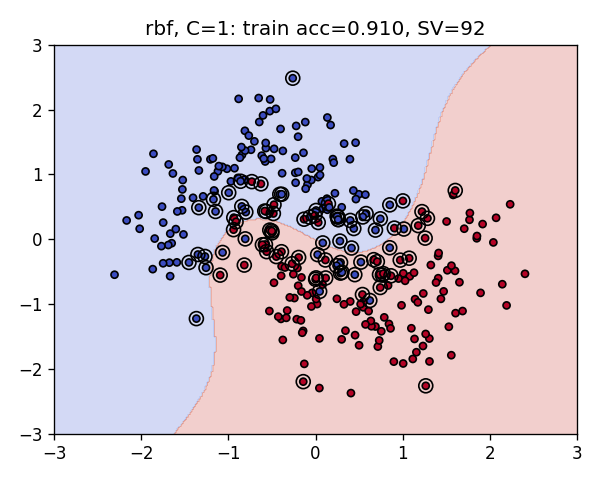

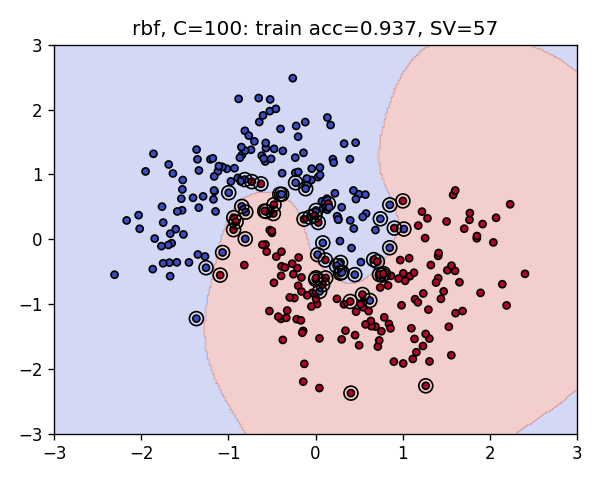

In [7]:
from IPython.display import Image, display
for f in ["svm_linear.png", "svm_rbf.png", "svm_rbf_C0.01.png", "svm_rbf_C1.png", "svm_rbf_C100.png"]:
    display(Image(f))

In [8]:
from google.colab import files
files.upload()

Saving o_churn_synthetic.csv to o_churn_synthetic.csv


{'o_churn_synthetic.csv': b'subscriber_code,region,tariff,tenure_months,monthly_charge_som,internet_gb,support_calls_3m,autopay,days_since_topup,topups_3m,dropped_calls_pct,balance_som,churn\n503715,\xd0\x91\xd0\xb8\xd1\x88\xd0\xba\xd0\xb5\xd0\xba,\xd0\x91\xd0\xb0\xd0\xb7\xd0\xbe\xd0\xb2\xd1\x8b\xd0\xb9,47,264,12.6,1,0,37,4,2.28,103,1\n844126,\xd0\x94\xd0\xb6\xd0\xb0\xd0\xbb\xd0\xb0\xd0\xbb-\xd0\x90\xd0\xb1\xd0\xb0\xd0\xb4\xd1\x81\xd0\xba\xd0\xb0\xd1\x8f,\xd0\xa1\xd0\xbc\xd0\xb0\xd1\x80\xd1\x82,54,472,19.9,0,1,12,7,1.4,184,0\n885657,\xd0\xa7\xd1\x83\xd0\xb9\xd1\x81\xd0\xba\xd0\xb0\xd1\x8f,\xd0\x91\xd0\xb0\xd0\xb7\xd0\xbe\xd0\xb2\xd1\x8b\xd0\xb9,1,291,12.9,0,1,3,9,2.98,11,0\n255447,\xd0\x9e\xd1\x88,\xd0\x91\xd0\xb0\xd0\xb7\xd0\xbe\xd0\xb2\xd1\x8b\xd0\xb9,29,273,7.1,0,0,17,6,2.16,137,0\n651577,\xd0\x9e\xd1\x88,\xd0\xa1\xd0\xbc\xd0\xb0\xd1\x80\xd1\x82,60,402,14.0,2,1,12,9,2.92,39,0\n707369,\xd0\x9d\xd0\xb0\xd1\x80\xd1\x8b\xd0\xbd\xd1\x81\xd0\xba\xd0\xb0\xd1\x8f,\xd0\x91\xd0\xb0\xd0\xb7\xd

In [9]:
import time
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC

df = pd.read_csv("o_churn_synthetic.csv")
X = df.drop(columns=["churn", "subscriber_code"])
y = df["churn"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

prep = ColumnTransformer(
    [("cat", OneHotEncoder(handle_unknown="ignore"), ["region", "tariff"])],
    remainder=StandardScaler())
svm = make_pipeline(prep, SVC(kernel="rbf"))

In [10]:
grid = {"svc__C": [0.1, 1, 10, 100], "svc__gamma": [0.001, 0.01, 0.1, 1]}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
search = GridSearchCV(svm, grid, cv=cv, scoring="roc_auc", n_jobs=-1)
t0 = time.perf_counter()
search.fit(X_train, y_train)
print(f"лучшие: {search.best_params_}  AUC CV={search.best_score_:.3f}"
      f"  поиск: {time.perf_counter() - t0:.0f} c")

table = pd.DataFrame(search.cv_results_).pivot(
    index="param_svc__C", columns="param_svc__gamma", values="mean_test_score")
print(table.round(3))

лучшие: {'svc__C': 10, 'svc__gamma': 0.001}  AUC CV=0.777  поиск: 34 c
param_svc__gamma  0.001  0.010  0.100  1.000
param_svc__C                                
0.1               0.771  0.772  0.763  0.655
1.0               0.774  0.776  0.745  0.655
10.0              0.777  0.761  0.694  0.646
100.0             0.774  0.739  0.646  0.646


In [11]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, roc_auc_score
from xgboost import XGBClassifier

tree_prep = ColumnTransformer(
    [("cat", OneHotEncoder(handle_unknown="ignore"), ["region", "tariff"])],
    remainder="passthrough")
models = {
    "SVM rbf (лучшая)": make_pipeline(prep, SVC(kernel="rbf", **{
        k.replace("svc__", ""): v for k, v in search.best_params_.items()})),
    "SVM linear": make_pipeline(prep, SVC(kernel="linear", C=1)),
    "Логрегрессия": make_pipeline(prep, LogisticRegression(max_iter=1000)),
    "Случайный лес": make_pipeline(tree_prep, RandomForestClassifier(
        n_estimators=100, random_state=42)),
    "XGBoost": make_pipeline(tree_prep, XGBClassifier(
        n_estimators=127, learning_rate=0.05, max_depth=3, random_state=42)),
}

In [12]:
for name, pipe in models.items():
    t0 = time.perf_counter()
    pipe.fit(X_train, y_train)
    sec = time.perf_counter() - t0
    f1 = f1_score(y_test, pipe.predict(X_test))
    scores = pipe.decision_function(X_test) if hasattr(pipe, "decision_function") \
        else pipe.predict_proba(X_test)[:, 1]
    auc = roc_auc_score(y_test, scores)
    print(f"{name:<18} F1 test={f1:.3f}  AUC test={auc:.3f}  {sec:.2f} c")

SVM rbf (лучшая)   F1 test=0.599  AUC test=0.801  0.20 c
SVM linear         F1 test=0.599  AUC test=0.798  0.29 c
Логрегрессия       F1 test=0.611  AUC test=0.806  0.03 c
Случайный лес      F1 test=0.556  AUC test=0.752  0.58 c
XGBoost            F1 test=0.586  AUC test=0.792  0.12 c


In [13]:
import time
from sklearn.datasets import make_classification
from sklearn.svm import SVC, LinearSVC

for n in [2000, 4000, 8000, 16000]:
    Xn, yn = make_classification(n_samples=n, n_features=20, random_state=42)
    t0 = time.perf_counter(); SVC(kernel="rbf").fit(Xn, yn); rbf = time.perf_counter() - t0
    t0 = time.perf_counter(); LinearSVC().fit(Xn, yn); lin = time.perf_counter() - t0
    print(f"n={n:<6} rbf SVC: {rbf:5.2f} c   LinearSVC: {lin:5.2f} c")

n=2000   rbf SVC:  0.08 c   LinearSVC:  0.00 c
n=4000   rbf SVC:  0.22 c   LinearSVC:  0.01 c
n=8000   rbf SVC:  1.49 c   LinearSVC:  0.01 c
n=16000  rbf SVC:  3.03 c   LinearSVC:  0.03 c
